In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
import math

In [9]:
df_raw = pd.read_csv('HHI Data 2024 United States.csv')
df_raw

,STATEFP10,STATE,STATE_ABV,ZCTA,GEOID10,MULTI_STATE,POP,PR_HRI,F_HRI,LOW_EMS,...,P_RENT,PR_RENT,P_OZONE,PR_OZONE,P_PM25,PR_PM25,NBE_SCORE,NBE_RANK,OVERALL_SCORE,OVERALL_RANK
0,25,MA,Massachusetts,1001,2501001,0,16769,64,0.75,0,...,27.047079,0.6068,0.333333,0.4580,0.000000,0.0000,0.4645,0.5632,0.5703,0.6978
1,25,MA,Massachusetts,1002,2501002,0,29049,67,0.75,0,...,50.989998,0.9119,0.000000,0.0000,0.000000,0.0000,0.3750,0.3196,0.4838,0.5314
2,25,MA,Massachusetts,1003,2501003,0,10372,20,0.25,1,...,90.476190,0.9898,0.000000,0.0000,0.000000,0.0000,0.3494,0.2550,0.4246,0.4113
3,25,MA,Massachusetts,1005,2501005,0,5079,20,0.25,0,...,13.888889,0.2152,0.000000,0.0000,0.000000,0.0000,0.2338,0.0655,0.2391,0.0968
4,25,MA,Massachusetts,1007,2501007,0,14649,58,0.75,0,...,18.551141,0.3538,0.500000,0.6086,0.000000,0.0000,0.3866,0.3498,0.3194,0.2106
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
32190,53,WA,Washington,99363,5399363,0,216,99,1.00,1,...,42.528736,0.8557,0.333333,0.4580,4.333333,0.9307,0.4980,0.6460,0.7150,0.8935
32191,53,WA,Washington,99371,5399371,0,311,99,1.00,0,...,30.303030,0.6834,0.333333,0.4580,6.000000,0.9481,0.6470,0.8948,0.8283,0.9755
32192,53,WA,Washington,99401,5399401,0,273,20,0.50,1,...,0.000000,0.0000,0.000000,0.0000,3.000000,0.9103,0.4175,0.4355,0.3667,0.2982
32193,53,WA,Washington,99402,5399402,0,1875,20,0.50,1,...,25.657895,0.5692,0.000000,0.0000,3.000000,0.9103,0.4533,0.5339,0.4457,0.4550


In [10]:
# Save a copy so we can keep df_raw for later
df = df_raw.copy()

In [11]:
# Define the columns we want to use
resp_col = [
    "PR_HRI" # Response variable
]
feature_cols = [
    #"ZCTA", # Do we even need the ZCTA?
    "P_NEHD",
    "P_CHD",
    "P_OBS",
    "P_DIABETES",
    "P_COPD",
    "P_ASTHMA",
    "P_MNTHL",
    "P_UNINSUR",
    "P_POV",
    "P_UNEMP",
    "P_NOHSDP",
    "P_ISO",
    "P_ELP",
    "P_DISABL",
    "P_ODW",
    "P_AGE65",
    "P_AGE5",
    "P_IMPERV",
    "P_TREEC",
    "P_NOVEH",
    "P_MOBILE",
    "P_RENT",
    "P_OZONE",
    "P_PM25"
]

# Isolate those columns and show what we have left
usecols = resp_col + feature_cols
df = df[usecols]
df

,PR_HRI,P_NEHD,P_CHD,P_OBS,P_DIABETES,P_COPD,P_ASTHMA,P_MNTHL,P_UNINSUR,P_POV,...,P_ODW,P_AGE65,P_AGE5,P_IMPERV,P_TREEC,P_NOVEH,P_MOBILE,P_RENT,P_OZONE,P_PM25
0,64,17.200000,6.8,31.8,10.1,7.3,11.4,16.3,3.7,14.411924,...,7.567814,23.5,5.5,24.875335,37.492276,8.6,0.4,27.047079,0.333333,0.000000
1,67,17.225000,4.1,23.3,6.8,5.1,12.1,20.2,2.7,35.434117,...,3.257099,13.4,2.9,4.647261,65.999638,9.7,0.1,50.989998,0.000000,0.000000
2,20,17.000000,1.0,22.2,2.0,3.4,15.4,33.8,3.8,80.232558,...,1.757147,0.0,0.0,54.066766,23.606311,0.0,0.0,90.476190,0.000000,0.000000
3,20,17.200000,5.4,31.4,8.3,6.4,11.7,16.2,0.3,9.863673,...,13.460857,15.5,2.5,2.074950,70.617445,3.9,3.5,13.888889,0.000000,0.000000
4,58,-999.000000,4.4,25.7,7.1,5.3,10.7,14.7,0.5,8.876532,...,8.151484,14.8,5.9,2.700549,62.296608,5.1,5.9,18.551141,0.500000,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
32190,99,14.600000,7.3,34.6,11.0,8.0,11.3,17.8,0.0,85.142857,...,31.395349,10.3,8.3,1.139955,1.162696,0.0,0.0,42.528736,0.333333,4.333333
32191,99,14.400000,8.5,35.3,12.6,9.2,11.4,15.6,4.6,23.076923,...,24.409449,21.2,7.1,0.691511,0.011863,3.0,27.6,30.303030,0.333333,6.000000
32192,20,14.400000,7.3,34.1,11.8,7.9,11.2,14.7,11.4,14.096186,...,29.133858,12.8,0.0,0.305686,20.116790,5.1,22.3,0.000000,0.000000,3.000000
32193,20,14.400000,6.1,32.9,9.9,6.8,11.4,16.1,5.4,18.490566,...,14.471780,29.5,4.8,0.390719,5.880173,1.5,11.3,25.657895,0.000000,3.000000


In [12]:
# Count how many rows have at least one NULL value
(df == -999).any(axis=1).sum()

np.int64(2074)

So 2074 out of 32195 ZCTAs have missing information in these columns. We can remove all of them and still have over 30,000 ZCTAs for our analysis, so let's do that.

In [13]:
# Filter for the rows with no NULL values
df = df[np.logical_not((df == -999).any(axis=1))]

# Check that now we have no NULL values
(df == -999).any(axis=1).sum()

np.int64(0)

Now we should plot the distributions of all the relevant variables.

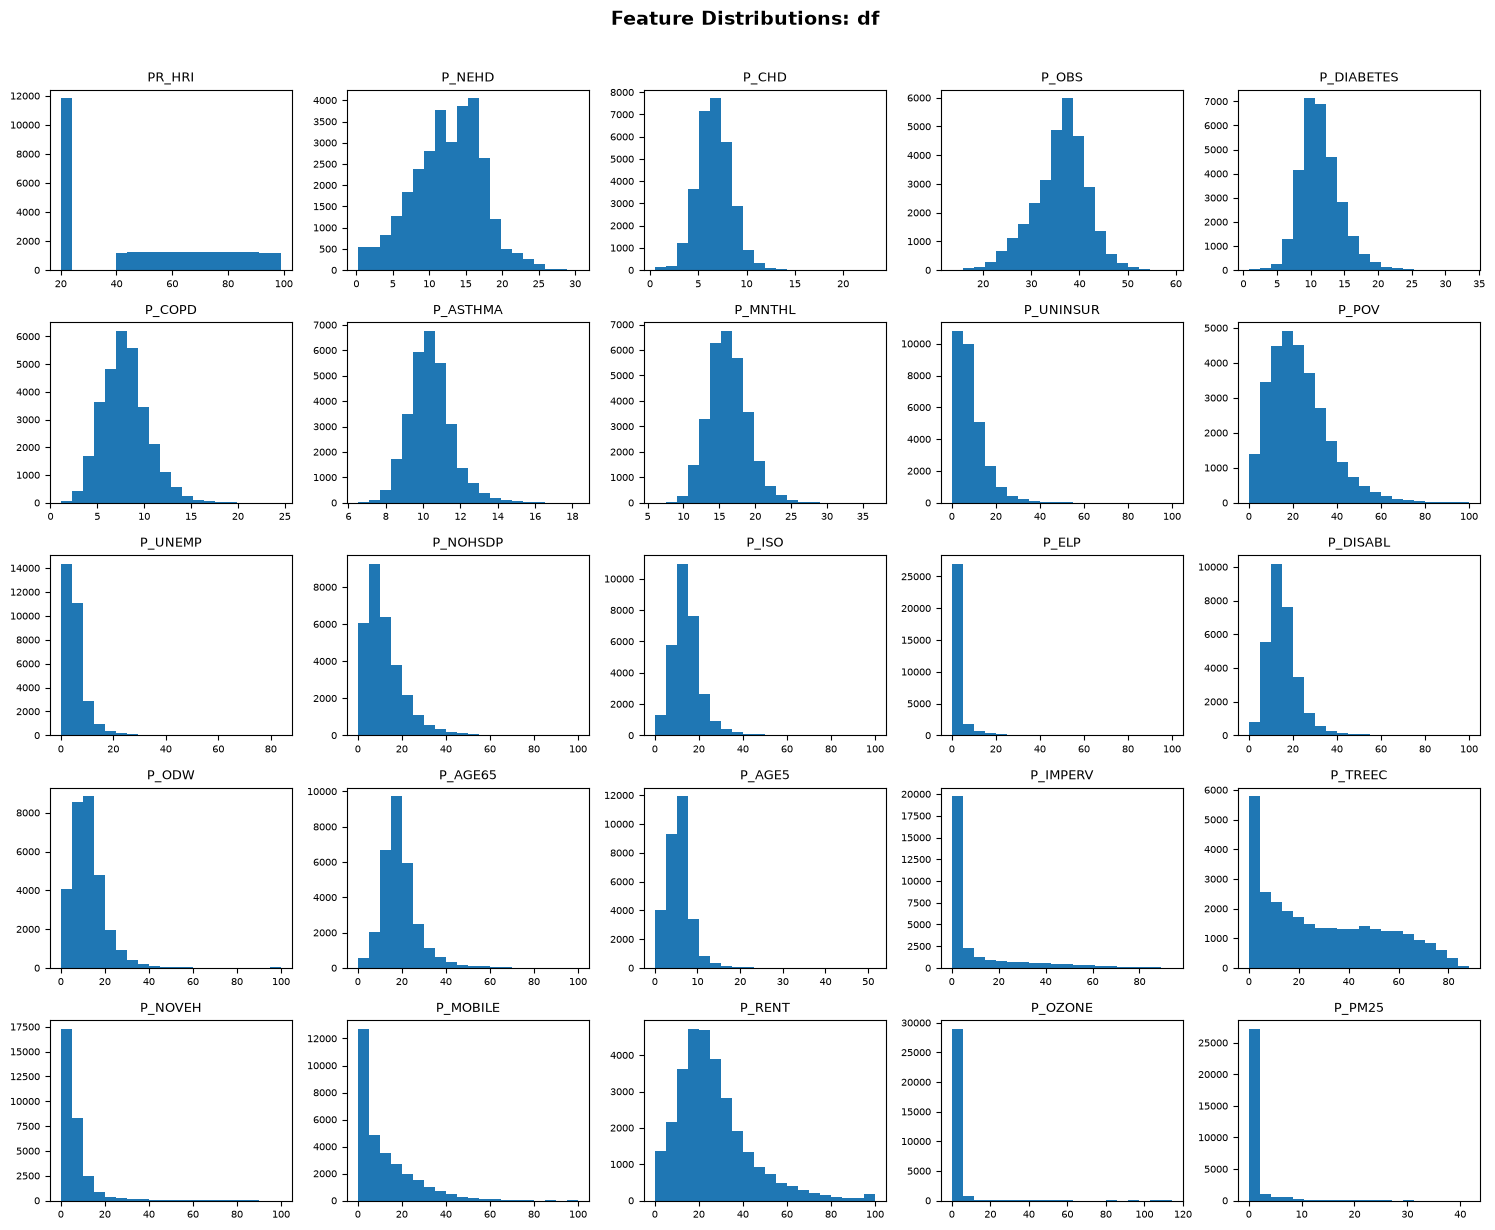

In [14]:
def plot_column_distributions(df, df_name):
    cols = df.columns
    n_cols = 5
    n_rows = math.ceil(len(cols) / n_cols)
    
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(3 * n_cols, 2.5 * n_rows))
    axes = axes.ravel()
    
    for ax, col in zip(axes, cols):
        ax.hist(df[col].dropna(), bins=20)
        ax.set_title(col, fontsize=9)
        ax.tick_params(labelsize=7)
    
    fig.suptitle(f"Feature Distributions: {df_name}", fontsize=14, fontweight="bold")
    fig.tight_layout(rect=[0, 0, 1, 0.97])  # leave a little space at the top
    plt.show()

plot_column_distributions(df, "df")

Important note: PR_HRI has a bit of an odd distribution. We would expect a PR_ column to be evenly distributed from 0-100, but it seems there are about ~12000 ZCTAs with NO heat-related illness EMS calls (which makes sense for cold regions), so they all get PR=20. The rest are evenly distributed from 40-100.

From here, we have decided to filter out the PR_HRI = 20 columns. I'll rerun the data processing steps from here including that filter. If I just filter here, we might unintentionally lose some rows that could be used in our analysis.

0


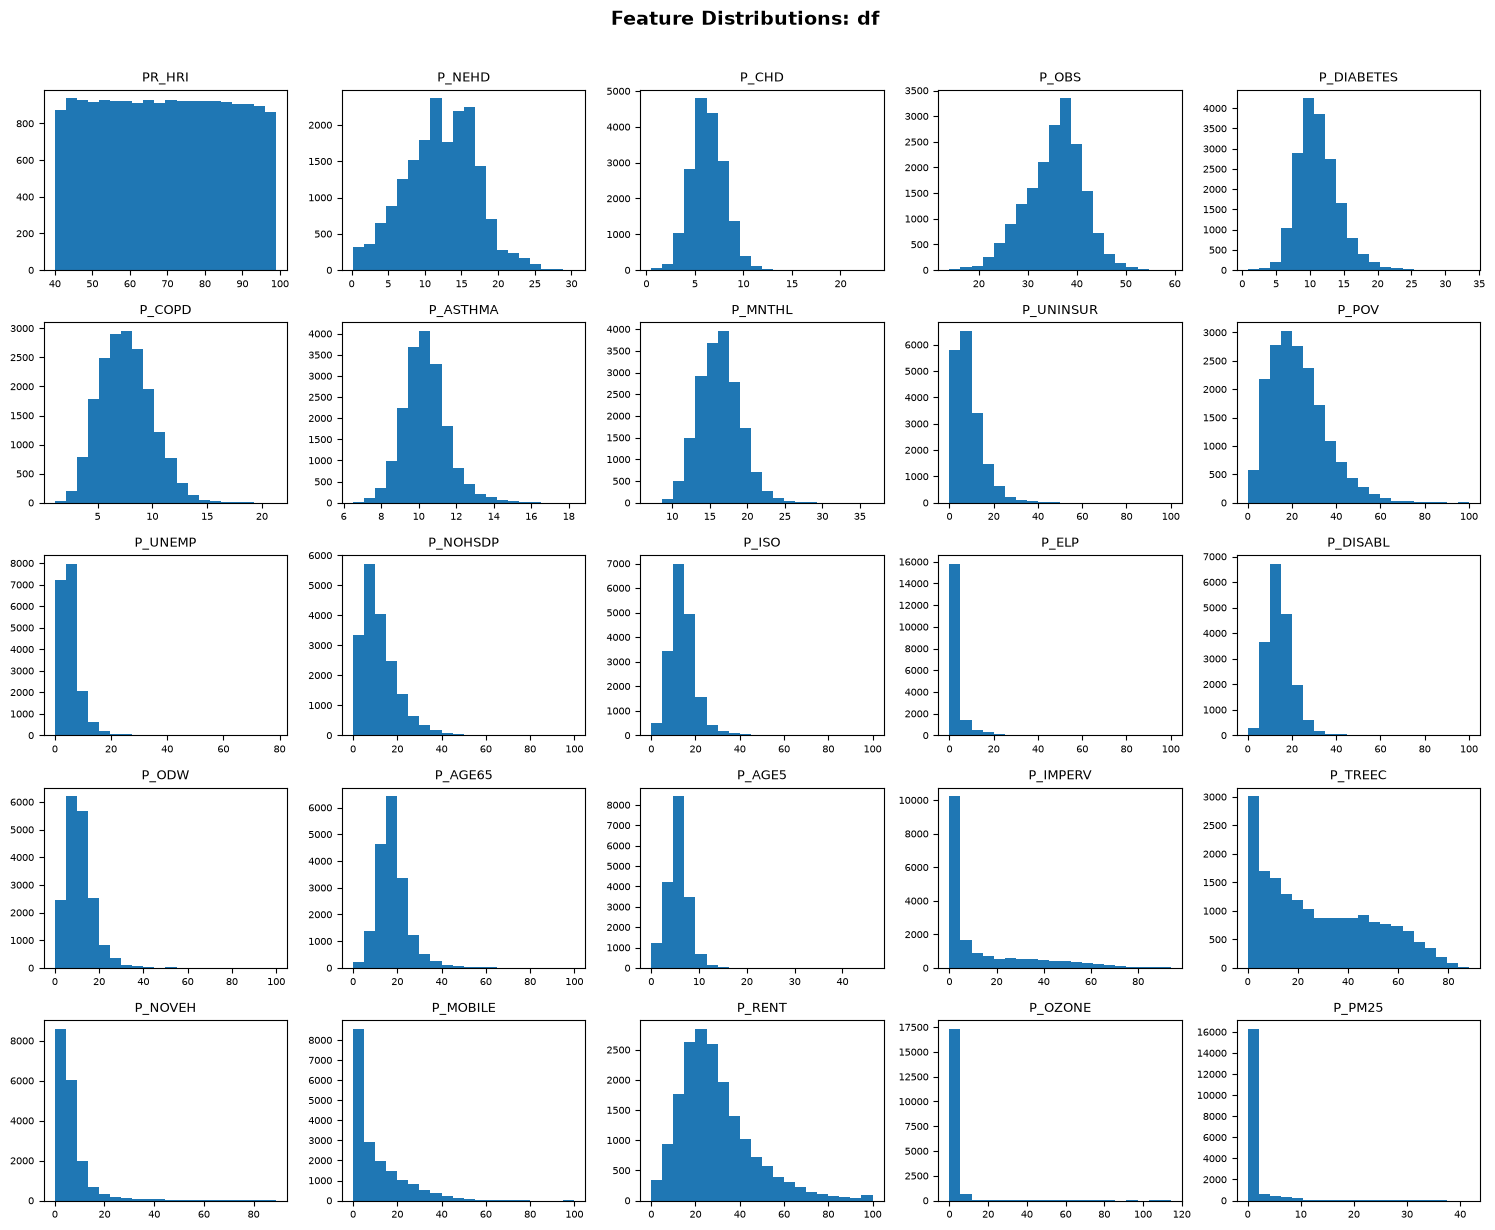

In [15]:
# Recopy the data and isolate the columns of interest
df = df_raw.copy()
df = df[usecols]

# Filter out the low PR_HRI rows
df = df[df['PR_HRI'] > 30]

# Count how many rows have at least one NULL value
(df == -999).any(axis=1).sum()

# Filter for the rows with no NULL values
df = df[np.logical_not((df == -999).any(axis=1))]

# Check that now we have no NULL values
print((df == -999).any(axis=1).sum())

plot_column_distributions(df, "df")

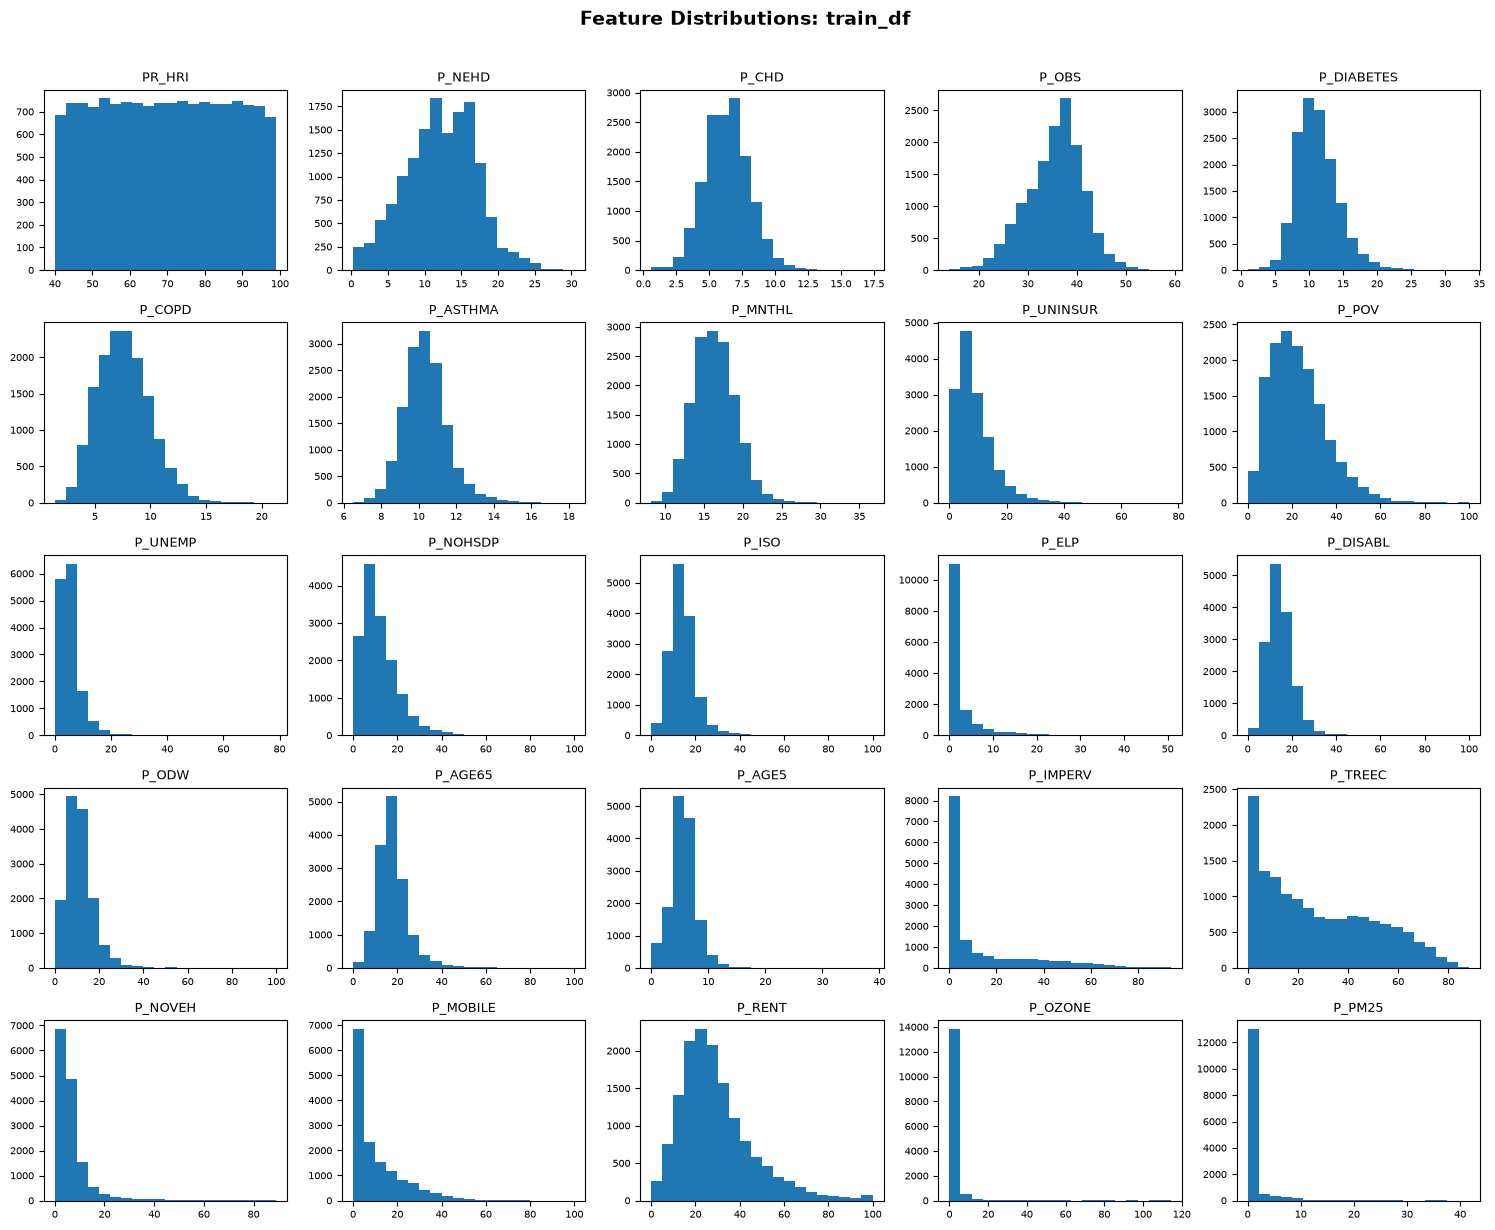

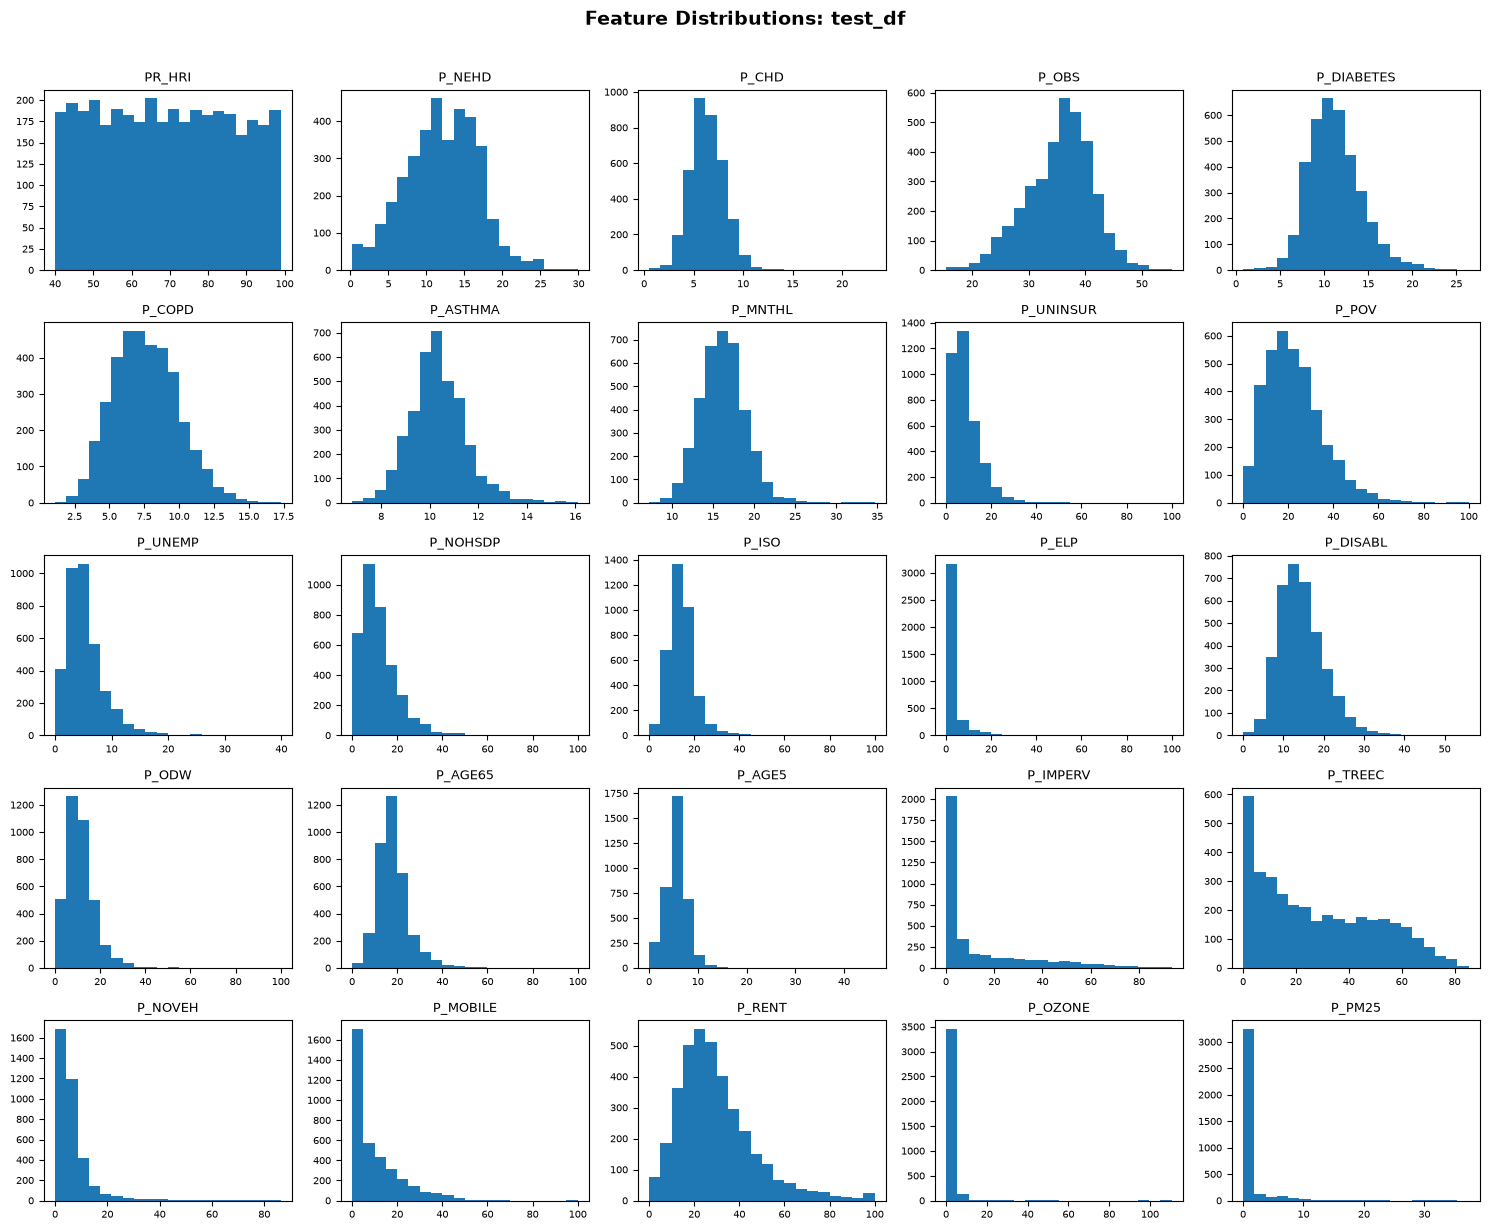

In [16]:
# Perform data split
# We shouldn't need to stratify since we have a lot of data and the response is fairly evenly distributed
# 80% train/val, 20% test
train_df, test_df = train_test_split(
    df,
    test_size=0.2,
    random_state=42,
)

# Check that not stratifying is reasonable by looking at the resulting distributions
plot_column_distributions(train_df, "train_df")
plot_column_distributions(test_df, "test_df")

The distributions look the same, so we are good to proceed.

Split each of the dataframes into feature matrix X and response y

In [17]:
X_train = train_df[feature_cols]
y_train = train_df[resp_col]

X_test = test_df[feature_cols]
y_test = test_df[resp_col]

In [18]:
# Just make sure the resulting dimensions look right
X_train.shape, y_train.shape, X_test.shape, y_test.shape

((14636, 24), (14636, 1), (3660, 24), (3660, 1))